In [1]:
"""
RAMAS - Automatic Detection of Subjunctive Mood Errors in EFL Learner Spanish
Pipeline: corpus loading → syntactic detection → DSI metrics → decision tree
Corpus: CEDEL2 (English L1 writers), processed with Stanza UD-Spanish
"""

# ════════════════════════════════════════════════════════════════
# DEPENDENCIES
# ════════════════════════════════════════════════════════════════
!pip install stanza pandas scikit-learn matplotlib lxml

import os
import zipfile
import numpy as np
import pandas as pd
import stanza
from collections import deque
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 794.2/794.2 kB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.7/418.7 kB 19.1 MB/s eta 0:00:00


In [2]:
# ════════════════════════════════════════════════════════════════
# STANZA PIPELINE — Spanish
# ════════════════════════════════════════════════════════════════
nlp = stanza.Pipeline(
    lang='es',
    processors='tokenize,pos,lemma,depparse',
    use_gpu=False,            # set True if CUDA is available
    tokenize_no_ssplit=False, # allow sentence segmentation
    verbose=False
)

# Quick sanity check
_doc = nlp("El análisis sintáctico con Stanza es eficiente.")
for _sent in _doc.sentences:
  for _w in _sent.words:
    print(f"Word: {_w.text:<12} | Lemma: {_w.lemma:<12} | "
          f"POS: {_w.upos:<6} | Head: {_w.head}")

models/tokenize/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B /  666kB            

models/tokenize/combined_nocharlm.pt: downloading bytes:           |  0.00B            

models/mwt/combined.pt: reconstructing file:   0%|          |  0.00B /  638kB            

models/mwt/combined.pt: downloading bytes:           |  0.00B            

models/pos/combined_charlm.pt: reconstructing file:   0%|          |  0.00B / 38.0MB            

models/pos/combined_charlm.pt: downloading bytes:           |  0.00B            

... (7 outputs left out)

models/forward_charlm/newswiki.pt: downloading bytes:           |  0.00B            

models/backward_charlm/newswiki.pt: reconstructing file:   0%|          |  0.00B / 20.0MB            

models/backward_charlm/newswiki.pt: downloading bytes:           |  0.00B            

Word: El           | Lemma: el           | POS: DET    | Head: 2
Word: análisis     | Lemma: análisis     | POS: NOUN   | Head: 7
Word: sintáctico   | Lemma: sintáctico   | POS: ADJ    | Head: 2
Word: con          | Lemma: con          | POS: ADP    | Head: 5
Word: Stanza       | Lemma: Stanza       | POS: PROPN  | Head: 2
Word: es           | Lemma: ser          | POS: AUX    | Head: 7
Word: eficiente    | Lemma: eficiente    | POS: ADJ    | Head: 0
Word: .            | Lemma: .            | POS: PUNCT  | Head: 7


In [6]:
# ════════════════════════════════════════════════════════════════
# CORPUS LOADING — from ZIP file
# ════════════════════════════════════════════════════════════════
from google.colab import files
uploaded     = files.upload()         # select your .zip when the dialog appears
ZIP_FILENAME = list(uploaded.keys())[0]


def score_to_cefr(score):
    """Map CEDEL2 placement test score (0-43) to proficiency band."""
    if score is None:
        return 'UNKNOWN'
    if 0  <= score <= 12: return 'lower_beginner'
    if 13 <= score <= 20: return 'upper_beginner'
    if 21 <= score <= 28: return 'lower_intermediate'
    if 29 <= score <= 35: return 'upper_intermediate'
    if 36 <= score <= 40: return 'lower_advanced'
    if 41 <= score <= 43: return 'upper_advanced'
    return 'UNKNOWN'


def parse_cedel2_txt(filename, content_bytes):
    """
    Parse a CEDEL2 TXT file from its filename and raw bytes.
    Expected filename format: L1_TASKTYPE_SCORE_AGE_YEARS_NTASK_SUBJECTID.txt
    e.g. EN_WR_41_22_7_1_DLM.txt
    """
    stem  = os.path.splitext(os.path.basename(filename))[0]
    parts = stem.split('_')
    text  = content_bytes.decode('utf-8', errors='replace').strip()

    if len(parts) < 7:
        return {
            'subject_id': stem, 'l1': 'UNKNOWN', 'task_type': 'UNKNOWN',
            'score': None, 'CEFR_level': 'UNKNOWN', 'age': None,
            'years_of_study': None, 'task_num': None, 'text': text
        }

    def safe_int(val):
      try:    return int(float(val))
      except: return None


    score = safe_int(parts[2])
    return {
        'subject_id'    : '_'.join(parts[6:]),
        'l1'           : parts[0],
        'task_type'  : parts[1],
        'score'        : score,
        'CEFR_level'   : score_to_cefr(score),
        'age'         : safe_int(parts[3]),
        'years_of_study': safe_int(parts[4]),
        'task_num'    : safe_int(parts[5]),
        'text'        : text
      }


def load_corpus_from_zip(zip_filename):
    """Load all .txt files from a ZIP archive, ignoring macOS metadata."""
    docs = []
    with zipfile.ZipFile(zip_filename, 'r') as zf:
        names = sorted([
            n for n in zf.namelist()
            if n.endswith('.txt') and not n.startswith('__MACOSX')
        ])
        print(f'TXT files found in ZIP: {len(names)}')
        for name in names:
            with zf.open(name) as f:
                docs.append(parse_cedel2_txt(name, f.read()))
    return docs


documents = load_corpus_from_zip(ZIP_FILENAME)
print(f'Documents loaded: {len(documents)}')

df_preview = pd.DataFrame(documents)
print(df_preview[['subject_id', 'CEFR_level', 'score']].to_string())

Saving Corpus_CEDEL2.zip to Corpus_CEDEL2.zip
TXT files found in ZIP: 75
Documents loaded: 75
   subject_id          CEFR_level  score
0         EAC  lower_intermediate     21
1         HIS  lower_intermediate     22
2         LMS  lower_intermediate     23
3         RAC  lower_intermediate     23
4         RRH  lower_intermediate     23
5          EW  lower_intermediate     24
6         SHB  lower_intermediate     24
7         KIF  lower_intermediate     24
8          RD  lower_intermediate     24
9          RK  lower_intermediate     24
10         AB  lower_intermediate     25
11         RK  lower_intermediate     26
12        EGP  lower_intermediate     26
13         JF  lower_intermediate     26
14          C  lower_intermediate     26
15        HNR  lower_intermediate     27
16        BJR  lower_intermediate     27
17        BSJ  lower_intermediate     27
18        KLC  lower_intermediate     28
19         CA  lower_intermediate     28
20         TH  lower_intermediate     28
21  

In [7]:
# ════════════════════════════════════════════════════════════════
# LINGUISTIC CONTROL LISTS
# ════════════════════════════════════════════════════════════════

# Volitional/emotive verbs: trigger obligatory subjunctive with subject change
VOLITIONAL_VERBS = {
    'querer','desear','esperar','pedir', 'rogar', 'necesitar',
    'insistir','exigir','recomendar','sugerir','ordenar',
    'proponer','preferir','permitir','prohibir','impedir',
    'dudar','negar','temer','lamentar','alegrarse',
    'sorprender','extrañar','parecer','suponer', 'apetecer',
    'suplicar', 'aconsejar', 'demandar', 'mandar', 'consentir',
    'autorizar', 'dejar', 'tolerar', 'convencer', 'persuadir'
}

# Final/purpose conjunctions: obligatorily followed by subjunctive
FINAL_CONNECTORS = {
    ('para', 'que'), ('antes', 'de', 'que'),
    ('sin', 'que'), ('a', 'menos', 'que'), ('a', 'menos', 'de', 'que'),
    ('con', 'tal', 'de', 'que'), ('con', 'tal', 'que'),
    ('a', 'fin', 'de', 'que'),
    ('de', 'modo', 'que'), ('de', 'manera', 'que'), ('de', 'forma', 'que'),
    ('una', 'vez', 'que'),
}

# Epistemic/reportative verbs: standard norm requires indicative;
# subjunctive after these = hypercorrection
INDICATIVE_TRIGGER_VERBS = {
    'creer','pensar','considerar','opinar','decir',
    'afirmar','saber','ver','notar','imaginar',
    'entender', 'comprender', 'suponer', 'asumir',
    'deducir', 'concluir', 'sospechar', 'juzgar',
    'observar', 'percibir',
    'oir', 'escuchar', 'comprobar', 'constatar',
    'asegurar', 'sostener', 'declarar', 'manifestar',
    'comunicar', 'informar', 'notificar', 'explicar',
    'exponer', 'señalar', 'apuntar', 'demostrar',
    'probar', 'recordar', 'olvidar'
}

# Evaluative predicates: trigger subjunctive as clausal subject/complement
EVALUATIVE_PREDICATES = {
    'importante', 'necesario', 'bueno', 'malo', 'mejor', 'peor',
    'esencial', 'fundamental', 'preferible', 'posible', 'imposible',
    'partidario', 'partidaria',
}

# Indefinite pronouns that can head a relative clause requiring subjunctive
INDEFINITE_PRONOUNS = {'alguien', 'nadie', 'algo', 'nada', 'quien', 'quienes'}

In [8]:
# ════════════════════════════════════════════════════════════════
# HELPER FUNCTIONS
# ════════════════════════════════════════════════════════════════

def get_feat(feats_str, feature_name):
  """
  Extract the value of a UD morphological feature from a Stanza feats string.
  e.g. get_feat('Mood=Sub|Number=Sing', 'Mood') -> 'Sub'
  """
  if not feats_str:
    return ''
  for feat in feats_str.split('|'):
      if feat.startswith(feature_name + '='):
        return feat.split('=')[1]
  return ''

def has_explicit_subject(v_sub, sentence):
    """
    Return True if the subordinate verb has its own explicit subject (nsubj),
    indicating a subject change relative to the matrix verb.
    Return False if the subject is likely coreferential (implicit, same subject).
    Coreferential infinitives are grammatically correct and should not be
    counted as elision errors.
    """
    return any(
        cand.head == v_sub.id and cand.deprel in ('nsubj', 'nsubj:pass')
        for cand in sentence.words
    )

In [9]:
import pandas as pd
import stanza
from collections import deque

# ════════════════════════════════════════════════════════════════
# SCENARIO DETECTORS
# ════════════════════════════════════════════════════════════════

def detect_scenario_A(sentence):
    """
    Scenario A — Volitional/epistemic matrix verb + subordinate clause.

    Correctly handles modal chains (e.g. 'espero que pueda viajar'):
    if the direct dependent is an infinitive, checks for a modal auxiliary
    bearing the Mood feature.

    Coreferential infinitives (same subject) are discarded, not counted as Elision.
    Indicative after INDICATIVE_TRIGGER_VERBS is discarded (not a subjunctive context).
    Subjunctive after INDICATIVE_TRIGGER_VERBS = Hypercorrection.
    """
    cases = []
    for w in sentence.words:
        if w.upos not in ('VERB', 'AUX'):
            continue
        lemma = w.lemma.lower()
        is_volitional  = lemma in VOLITIONAL_VERBS
        is_ind_trigger = lemma in INDICATIVE_TRIGGER_VERBS
        if not (is_volitional or is_ind_trigger):
            continue

        # Collect all direct ccomp/xcomp dependents
        candidates = [
            c for c in sentence.words
            if c.head == w.id and c.upos in ('VERB', 'AUX')
            and c.deprel in ('ccomp', 'xcomp')
        ]
        if not candidates:
            continue

        v_sub     = candidates[0]
        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        # Handle modal chains: if v_sub is bare infinitive, check for
        # an auxiliary (e.g. 'pueda') that carries the actual Mood
        if verb_form == 'Inf' and not mood:
            for aux in sentence.words:
                if aux.head == v_sub.id and aux.deprel == 'aux' and aux.upos == 'AUX':
                    mood_aux = get_feat(aux.feats, 'Mood')
                    if mood_aux in ('Sub', 'Ind'):
                        v_sub     = aux
                        verb_form = get_feat(aux.feats, 'VerbForm')
                        mood      = mood_aux
                        break

        target = None
        if is_volitional and verb_form == 'Inf':
            # Coreferential infinitive = grammatical, not an error
            target = 'Elision' if has_explicit_subject(v_sub, sentence) else None
        elif is_volitional and mood == 'Sub':
            target = 'Correct'
        elif is_volitional and mood == 'Ind':
            target = 'Indicative_Elision'
        elif is_ind_trigger and mood == 'Sub':
            target = 'Hipercorreccion'
        elif is_ind_trigger and mood == 'Ind':
            target = None   # indicative is the only correct option here

        if target:
            cases.append({
                'id_matrix_verb': w.id,
                'matrix_lemma'    : lemma,
                'matrix_type'    : 'Volition' if is_volitional else 'Indicative_Trigger',
                'id_sub_verb'   : v_sub.id,
                'sub_form'      : v_sub.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases


def detect_scenario_B(sentence):
    """
    Scenario B — Indefinite noun phrase or indefinite pronoun + relative clause.

    The relative clause verb should be in subjunctive (inespecific/hypothetical
    referent). Indicative in this context = Elision.

    Past-tense indicative relatives are excluded: if the event already occurred,
    the referent is specific and indicative is correct.
    """
    cases = []
    INDEFINITE_DETERMINERS = {
        'un', 'uno', 'una',
        'todo', 'toda', 'todos', 'todas',
        'cualquier', 'cualquiera',
        'algún', 'alguno', 'alguna', 'algunos', 'algunas',
        'ningún', 'ninguno', 'ninguna',
    }

    nucleus_candidates = []
    for w in sentence.words:
        if w.upos == 'NOUN':
            has_indef = any(
                d.head == w.id and d.deprel == 'det'
                and d.lemma.lower() in INDEFINITE_DETERMINERS
                for d in sentence.words
            )
            if has_indef:
                nucleus_candidates.append(w)
        elif w.upos == 'PRON' and w.lemma.lower() in INDEFINITE_PRONOUNS:
            nucleus_candidates.append(w)

    for nucleus in nucleus_candidates:
        for v_rel in sentence.words:
            if v_rel.head != nucleus.id or v_rel.deprel not in ('acl:relcl', 'acl'):
                continue
            if v_rel.upos not in ('VERB', 'AUX'):
                continue

            verb_form = get_feat(v_rel.feats, 'VerbForm')
            mood      = get_feat(v_rel.feats, 'Mood')
            tense     = get_feat(v_rel.feats, 'Tense')

            # Exclude past indicative: specific referent, indicative is correct
            if tense in ('Past', 'Imp') and mood == 'Ind':
                continue

            if verb_form == 'Inf':
                target = 'Elision'
            elif mood == 'Sub':
                target = 'Correct'
            elif mood == 'Ind':
                target = 'Indicative_Elision'
            else:
                continue

            cases.append({
                'id_matrix_verb': nucleus.id,
                'matrix_lemma'    : nucleus.lemma,
                'matrix_type'    : 'Indefinite_Relative',
                'id_sub_verb'   : v_rel.id,
                'sub_form'      : v_rel.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases

def detect_scenario_C(sentence):
    """
    Scenario C — Final/purpose conjunctions followed by verb.
    Subjunctive obligatory after all connectors in FINAL_CONNECTORS.
    Infinitive or indicative after them = Elision.
    """
    cases        = []
    words        = sentence.words
    tokens_lower = [w.text.lower() for w in words]

    for i, w in enumerate(words):
        connector_found = None
        connector_len   = 0
        for conn in FINAL_CONNECTORS:
            n = len(conn)
            if tokens_lower[i:i + n] == list(conn):
                connector_found = conn
                connector_len = n
                break

        if connector_found is None:
            continue

        next_idx = i + connector_len
        if next_idx >= len(words):
            continue

        v_sub = words[next_idx]
        if v_sub.upos not in ('VERB', 'AUX'):
            found = False
            for j in range(next_idx, min(next_idx + 3, len(words))):
                if words[j].upos in ('VERB', 'AUX'):
                    v_sub = words[j]
                    found = True
                    break
            if not found:
                continue

        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        if verb_form == 'Inf':
            target = 'Elision'
        elif mood == 'Sub':
            target = 'Correct'
        elif mood == 'Ind':
            target = 'Indicative_Elision'
        else:
            continue


        cases.append({
            'id_matrix_verb': w.head,
            'matrix_lemma'    : ' '.join(connector_found),
            'matrix_type'    : 'Final_Conector',
            'id_sub_verb'    : v_sub.id,
            'sub_form'      : v_sub.text,
            'verb_form'      : verb_form,
            'mood'           : mood,
            'target_class'   : target
        })
    return cases

def detect_scenario_D(sentence):
    """
    Scenario D — Evaluative predicate (adjective/noun) + subordinate clause.
    e.g. 'es importante que', 'no soy partidaria de que'.

    Handles nested copular structures: if the direct dependent is a predicative
    adjective with its own copula, the copula carries the actual Mood.

    Coreferential infinitives (generic impersonal constructions such as
    'es fundamental cambiar') are excluded, not counted as Elision.
    """
    cases = []
    for w in sentence.words:
        if w.upos not in ('ADJ', 'NOUN'):
            continue
        if w.lemma.lower() not in EVALUATIVE_PREDICATES:
            continue

        v_sub = None
        for cand in sentence.words:
            if cand.head != w.id:
                continue
            if cand.upos in ('VERB', 'AUX') and cand.deprel in ('ccomp', 'csubj', 'advcl'):
                v_sub = cand
                break
            # Nested copular predicate: 'no soy partidaria de que esté casada'
            if cand.upos == 'ADJ' and cand.deprel == 'acl':
                for cop in sentence.words:
                    if cop.head == cand.id and cop.deprel == 'cop' and cop.upos == 'AUX':
                        v_sub = cop
                        break
                if v_sub:
                    break

        if v_sub is None:
            continue

        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        target = None
        if verb_form == 'Inf':
          # Generic impersonal infinitive = grammatical, not an error
           target = 'Elision' if has_explicit_subject(v_sub, sentence) else None
        elif mood == 'Sub':
            target = 'Correct'
        elif mood == 'Ind':
            target = 'Indicative_Elision'

        if target:
            cases.append({
                'id_matrix_verb': w.id,
                'matrix_lemma'    : w.lemma,
                'matrix_type'    : 'Evaluative_Predicate',
                'id_sub_verb'   : v_sub.id,
                'sub_form'      : v_sub.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases


In [10]:
# ════════════════════════════════════════════════════════════════
# SYNTACTIC METRICS
# ════════════════════════════════════════════════════════════════

def calculate_dsi(sentence, id_matrix_verb, id_sub_verb):
    """
    Interverbal Syntactic Distance (DSI) between two verbs.

    Returns:
        linear_distance      (DL): linear token distance between the two verbs
        syntactic_depth (PS): graph distance in the dependency tree (BFS)

    Based on Liu (2008) — Mean Dependency Distance as a measure of
    syntactic processing complexity.
    """
    DL = max(0, abs(id_sub_verb - id_matrix_verb) - 1)

    graph = {w.id: [] for w in sentence.words}
    graph[0] = []
    for w in sentence.words:
        graph[w.id].append(w.head)
        graph.setdefault(w.head, []).append(w.id)

    visited = {id_matrix_verb}
    queue   = deque([(id_matrix_verb, 0)])
    PS      = -1
    while queue:
        node, dist = queue.popleft()
        if node == id_sub_verb:
            PS = dist
            break
        for neighbour in graph.get(node, []):
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append((neighbour, dist + 1))

    return {'linear_distance': DL, 'syntactic_depth': PS}


def calculate_mdd(sentence):
    """Mean Dependency Distance (MDD for the ful sentence (Liu, 2008)."""
    distances = [abs(w.id - w.head) for w in sentence.words if w.head != 0]
    return sum(distances) / len(distances) if distances else 0.0

In [11]:
# ════════════════════════════════════════════════════════════════
# STEP A — Detector verification on control sentences
# ════════════════════════════════════════════════════════════════

CONTROL_SENTENCES = [
    ("Quisiera obtener un trabajo.",           "[] - coreferential infinitive, no case"),
    ("Pienso que tienes razón.",               "[] - indicative trigger + Ind, no case"),
    ("Espero que pueda viajar mañana.",        "Scenario A: Correct (modal chain)"),
    ("Es importante que vengas temprano.",     "Scenario D: Correct (evaluative predicative)"),
    ("Necesito a alguien que me ayude.",       "Scenario B: Correct (indefinite pronoun)"),
    ("Lo haré de modo que todos entiendan.",   "Scenario C: Correct (extended connector)"),
]

print("=" * 70)
print("STEP A - CONTROL SENTENCE VERIFICATION")
print("=" * 70)
for sentence_text, expected in CONTROL_SENTENCES:
    doc = nlp(sentence_text)
    for sent in doc.sentences:
        a = detect_scenario_A(sent)
        b = detect_scenario_B(sent)
        c = detect_scenario_C(sent)
        d = detect_scenario_D(sent)
        print(f"\nSentence : {sentence_text}")
        print(f"Expected : {expected}")
        print(f"  A: {a}")
        print(f"  B: {b}")
        print(f"  C: {c}")
        print(f"  D: {d}")

STEP A - CONTROL SENTENCE VERIFICATION

Sentence : Quisiera obtener un trabajo.
Expected : [] - coreferential infinitive, no case
  A: []
  B: []
  C: []
  D: []

Sentence : Pienso que tienes razón.
Expected : [] - indicative trigger + Ind, no case
  A: []
  B: []
  C: []
  D: []

Sentence : Espero que pueda viajar mañana.
Expected : Scenario A: Correct (modal chain)
  A: [{'id_matrix_verb': 1, 'matrix_lemma': 'esperar', 'matrix_type': 'Volition', 'id_sub_verb': 3, 'sub_form': 'pueda', 'verb_form': 'Fin', 'mood': 'Sub', 'target_class': 'Correct'}]
  B: []
  C: []
  D: []

Sentence : Es importante que vengas temprano.
Expected : Scenario D: Correct (evaluative predicative)
  A: []
  B: []
  C: []
  D: [{'id_matrix_verb': 2, 'matrix_lemma': 'importante', 'matrix_type': 'Evaluative_Predicate', 'id_sub_verb': 4, 'sub_form': 'vengas', 'verb_form': 'Fin', 'mood': 'Ind', 'target_class': 'Indicative_Elision'}]

Sentence : Necesito a alguien que me ayude.
Expected : Scenario B: Correct (indefin

In [12]:
# ════════════════════════════════════════════════════════════════
# STEP B — Process each document in the corpus
# ════════════════════════════════════════════════════════════════

def process_document(doc_dict, nlp_pipeline):
    """
    Run all four scenario detectors over a single corpus document.
    Returns a list of case dictionaries with DSI and MDD metrics.
    """
    subject_id = doc_dict['subject_id']
    cefr_level = doc_dict['CEFR_level']
    text       = doc_dict['text']

    if not text or not text.strip():
        return []

    try:
        doc = nlp_pipeline(text)
    except Exception as exc:
        print(f'\n⚠️  Error processing {subject_id}: {exc}')
        return []

    rows = []
    for sentence in doc.sentences:
        detectors = [
            detect_scenario_A(sentence),
            detect_scenario_B(sentence),
            detect_scenario_C(sentence),
            detect_scenario_D(sentence),
        ]
        for cases in detectors:
            for case in cases:
              dsi = calculate_dsi(
                  sentence,
                  case['id_matrix_verb'],
                  case['id_sub_verb']
              )
              mdd = calculate_mdd(sentence)

              matrix_type = case['matrix_type']
              if matrix_type in ('Volition', 'Final_Conector',
                                 'Indefinite_Relative', 'Evaluative_Predicate'):
                model = 'M1_elision'
              elif matrix_type == 'Indicative_Trigger':
                model = 'M2_hypercorrection'
              else:
                model = 'UNKNOWN'

              rows.append({
                    'ID_Subject'          : subject_id,
                    'Model'               : model,
                    'CEFR_Level'          : cefr_level,
                    'Matrix_Type'         : case['matrix_type'],
                    'Trigger_Lemma'       : case['matrix_lemma'],
                    'SubVerb_Form'        : case['sub_form'],
                    'Linear_Distance'     : dsi['linear_distance'],
                    'Syntactic_Depth'     : dsi['syntactic_depth'],
                    'MDD_Sentence'        : round(mdd, 3),
                    'Target_Class'        : case['target_class'],
                })
    return rows

# Run over the full corpus
results = []
for i, doc_dict in enumerate(documents, 1):
    print(f'Processing {i}/{len(documents)}: {doc_dict["subject_id"]}')
    results.extend(process_document(doc_dict, nlp))

df = pd.DataFrame(results)
print(f'\nTotal cases detected: {len(df)}')

if len(df) > 0:
    print(df['Target_Class'].value_counts())
else:
    print('No cases detected. Check that the texts contain the expected patterns.')


Processing 1/75: EAC
Processing 2/75: HIS
Processing 3/75: LMS
Processing 4/75: RAC
Processing 5/75: RRH
Processing 6/75: EW
Processing 7/75: SHB
Processing 8/75: KIF
Processing 9/75: RD
Processing 10/75: RK
Processing 11/75: AB
Processing 12/75: RK
Processing 13/75: EGP
Processing 14/75: JF
Processing 15/75: C
Processing 16/75: HNR
Processing 17/75: BJR
Processing 18/75: BSJ
Processing 19/75: KLC
Processing 20/75: CA
Processing 21/75: TH
Processing 22/75: THM
Processing 23/75: AM
Processing 24/75: KW
Processing 25/75: CMF
Processing 26/75: AJJ
Processing 27/75: RCR
Processing 28/75: MK
Processing 29/75: RCF
Processing 30/75: MAH
Processing 31/75: SP
Processing 32/75: CALS
Processing 33/75: JJNE
Processing 34/75: AA
Processing 35/75: AJ
Processing 36/75: JMG
Processing 37/75: KS
Processing 38/75: ASA
Processing 39/75: HES
Processing 40/75: CAL
Processing 41/75: KB
Processing 42/75: REB
Processing 43/75: LS
Processing 44/75: SCR
Processing 45/75: JAS
Processing 46/75: LJ
Processing 47/7

In [17]:
# ════════════════════════════════════════════════════════════════
# STEP C — Dataset cleaning and CEFR level mapping
# ════════════════════════════════════════════════════════════════
if len(df) == 0:
    raise ValueError("Empty DataFrame — check Step B before continuing.")

# Remove cases where the dependency path was not found (PS == -1)
before = len(df)
df = df[df['Syntactic_Depth'] != -1].copy()
print(f"Rows removed (Syntactic_Depth == -1): {before - len(df)}")

# Map CEDEL2 internal bands to three CEFR levels used in the study.
# lower_beginner excluded (too few subjunctive contexts at that level).
# Mapping rationale (Gudmestad 2006; CEDEL2 documentation):
#   upper_beginner + lower_intermediate → B1
#   upper_intermediate                  → B2
#   lower_advanced + upper_advanced     → C1
cefr_mapping = {
    'lower_beginner'    : 'A1',
    'upper_beginner'    : 'A2',
    'lower_intermediate': 'B1',
    'upper_intermediate': 'B2',
    'lower_advanced'    : 'C1',
    'upper_advanced'    : 'C2',
}
df['CEFR_Level'] = df['CEFR_Level'].astype(str).map(cefr_mapping)

before = len(df)
df.dropna(subset=['CEFR_Level'], inplace=True)
discarded = before - len(df)
if discarded > 0:
    print(f"⚠  {discarded} rows discarded (unmappable level, e.g. lower_beginner).")

# Unify Indicative_Elision into Elision before stratified split
print(df.groupby(['CEFR_Level', 'Target_Class']).size().unstack(fill_value=0))
df['Target_Class_merged'] = df['Target_Class'].replace(
    'Indicative_Elision', 'Elision'
)

df['Linear_Distance'] = df['Linear_Distance'].astype(int)
df['CEFR_Level'] = pd.Categorical(
    df['CEFR_Level'], categories=['B1', 'B2', 'C1'], ordered=True
)

print(f"\nTotal cases after cleaning: {len(df)}")
print(df[['CEFR_Level', 'Target_Class']].value_counts().sort_index())

# Export full annotated dataset for audit
df.to_csv('dataset_subjunctive.csv', index=False, encoding='utf-8-sig')
print("\nDataset exported → dataset_subjunctive.csv")

# Split into the two models
df_m1 = df[df['Model'] == 'M1_elision'].copy()
df_m1 = df_m1[df_m1['Target_Class_merged'].isin(['Correct', 'Elision'])]
df_m1['Binary_Target'] = (df_m1['Target_Class_merged'] == 'Correct').astype(int)

df_m2 = df[df['Model'] == 'M2_hypercorrection'].copy()
df_m2 = df_m2[df_m2['Target_Class_merged'].isin(['Correct', 'Hipercorreccion'])]
df_m2['Binary_Target'] = (df_m2['Target_Class_merged'] == 'Correct').astype(int)

print(f'\nM1 (elision):        {len(df_m1)} cases'
      f' — Correct: {(df_m1["Target_Class"]=="Correct").sum()}'
      f', Elision: {(df_m1["Target_Class"]=="Elision").sum()}')
print(f'M2 (hypercorrection): {len(df_m2)} cases'
      f' — Hipercorreccion: {(df_m2["Target_Class"]=="Hipercorreccion").sum()}')

Rows removed (Syntactic_Depth == -1): 0
Target_Class  Correct  Elision  Hipercorreccion  Indicative_Elision
CEFR_Level                                                         
B1                  8        7                1                  20
B2                 11        9                3                  44
C1                 20       12                8                  35

Total cases after cleaning: 178
CEFR_Level  Target_Class      
B1          Correct                8
            Elision                7
            Hipercorreccion        1
            Indicative_Elision    20
B2          Correct               11
            Elision                9
            Hipercorreccion        3
            Indicative_Elision    44
C1          Correct               20
            Elision               12
            Hipercorreccion        8
            Indicative_Elision    35
Name: count, dtype: int64

Dataset exported → dataset_subjunctive.csv

M1 (elision):        166 cases — Correct:

In [18]:
# ════════════════════════════════════════════════════════════════
# STEP D — Feature encoding and decision tree training
# ════════════════════════════════════════════════════════════════
CEFR_ORDER = ['B1', 'B2', 'C1']
le_cefr = LabelEncoder()
le_cefr.fit(CEFR_ORDER)

df_m1 = df_m1.copy()
df_m2 = df_m2.copy()

# Remove NaN values from CEFR_Level in df_m1 and df_m2.
# These NaNs were introduced by the pd.Categorical conversion in the previous step
# (converting 'A1', 'A2', 'C2' to NaN, as they are not in the specified categories).
df_m1.dropna(subset=['CEFR_Level'], inplace=True)
df_m2.dropna(subset=['CEFR_Level'], inplace=True)

df_m1['CEFR_encoded'] = le_cefr.transform(df_m1['CEFR_Level'])
df_m2['CEFR_encoded'] = le_cefr.transform(df_m2['CEFR_Level'])

FEATURES = ['Linear_Distance', 'Syntactic_Depth', 'MDD_Sentence', 'CEFR_encoded']

# ── M1: Obligatory subjunctive contexts — Correct vs Elision ──
print("\n" + "═" * 70)
print("TREE M1 — Obligatory subjunctive (Correct vs Elision)")
print("═" * 70)

if len(df_m1) < 10:
    print(f"⚠  Only {len(df_m1)} cases in M1. Expand the corpus before interpreting results.")
else:
    X1 = df_m1[FEATURES].values
    y1 = df_m1['Binary_Target'].values

    min_class_m1 = pd.Series(y1).value_counts().min()

    try:
        X1_train, X1_test, y1_train, y1_test = train_test_split(
            X1, y1, test_size=0.25, random_state=42, stratify=y1
        )
    except ValueError as e:
        print(f"⚠  Stratified split failed ({e}). Using simple split.")
        X1_train, X1_test, y1_train, y1_test = train_test_split(
            X1, y1, test_size=0.25, random_state=42
        )

    tree_m1 = DecisionTreeClassifier(
        criterion='gini', max_depth=3, min_samples_leaf=3,
        class_weight='balanced', random_state=42
    )
    tree_m1.fit(X1_train, y1_train)
    y1_pred = tree_m1.predict(X1_test)

    print("\n--- Classification Report M1 ---")
    print(classification_report(
        y1_test, y1_pred, target_names=['Elision', 'Correct'], zero_division=0
    ))

    cv_folds_m1 = min(5, min_class_m1) if min_class_m1 >= 2 else None
    if cv_folds_m1 and cv_folds_m1 >= 2:
        scores_m1 = cross_val_score(tree_m1, X1, y1, cv=cv_folds_m1, scoring='f1_macro')
        print(f'F1-macro CV M1 ({cv_folds_m1}-fold): '
              f'{scores_m1.mean():.3f} ± {scores_m1.std():.3f}')
    else:
        print("⚠  Insufficient examples per class for cross-validation in M1.")

    print("\n── Decision Rules M1 ──")
    print(export_text(tree_m1, feature_names=FEATURES))

    importances_m1 = pd.Series(
        tree_m1.feature_importances_, index=FEATURES
    ).sort_values(ascending=False)
    print('\nFeature Importance M1 (Gini):')
    print(importances_m1.to_string())

# ── M2: Indicative-trigger contexts — Correct vs Hypercorrection ──
print("\n" + "═" * 70)
print("TREE M2 — Indicative-trigger contexts (Correct vs Hypercorrection)")
print("═" * 70)

n_classes_m2 = df_m2['Target_Class'].nunique() if len(df_m2) > 0 else 0

if len(df_m2) < 10:
    print(f"⚠  Only {len(df_m2)} cases in M2. Descriptive analysis only.")
    if len(df_m2) > 0:
        print(df_m2[['CEFR_Level', 'Target_Class', 'Linear_Distance']].to_string())
elif n_classes_m2 < 2:
    print(f"⚠  M2 has {len(df_m2)} cases but only one class "
          f"('{df_m2['Target_Class'].iloc[0]}'). Descriptive analysis only.")
    print(df_m2[['CEFR_Level', 'Target_Class', 'Linear_Distance']].to_string())
    print("\nDSI descriptive statistics by class:")
    print(df_m2.groupby('Target_Class')['Linear_Distance']
          .agg(['mean', 'std', 'count']).round(2))
else:
    X2 = df_m2[FEATURES].values
    y2 = df_m2['Binary_Target'].values

    min_class_m2 = pd.Series(y2).value_counts().min()

    try:
        X2_train, X2_test, y2_train, y2_test = train_test_split(
            X2, y2, test_size=0.25, random_state=42, stratify=y2
        )
    except ValueError as e:
        print(f"⚠  Stratified split failed ({e}). Using simple split.")
        X2_train, X2_test, y2_train, y2_test = train_test_split(
            X2, y2, test_size=0.25, random_state=42
        )

    tree_m2 = DecisionTreeClassifier(
        criterion='gini', max_depth=3, min_samples_leaf=3,
        class_weight='balanced', random_state=42
    )
    tree_m2.fit(X2_train, y2_train)
    y2_pred = tree_m2.predict(X2_test)

    print("\n--- Classification Report M2 ---")
    print(classification_report(
        y2_test, y2_pred,
        target_names=['Correct', 'Hypercorrection'], zero_division=0
    ))

    cv_folds_m2 = min(5, min_class_m2) if min_class_m2 >= 2 else None
    if cv_folds_m2 and cv_folds_m2 >= 2:
        scores_m2 = cross_val_score(tree_m2, X2, y2, cv=cv_folds_m2, scoring='f1_macro')
        print(f'F1-macro CV M2 ({cv_folds_m2}-fold): '
              f'{scores_m2.mean():.3f} ± {scores_m2.std():.3f}')
    else:
        print("⚠  Insufficient examples per class for cross-validation in M2.")

    print("\n── Decision Rules M2 ──")
    print(export_text(tree_m2, feature_names=FEATURES))

    importances_m2 = pd.Series(
        tree_m2.feature_importances_, index=FEATURES
    ).sort_values(ascending=False)
    print('\nFeature Importance M2 (Gini):')
    print(importances_m2.to_string())


══════════════════════════════════════════════════════════════════════
TREE M1 — Obligatory subjunctive (Correct vs Elision)
══════════════════════════════════════════════════════════════════════

--- Classification Report M1 ---
              precision    recall  f1-score   support

     Elision       0.81      0.69      0.75        32
     Correct       0.33      0.50      0.40        10

    accuracy                           0.64        42
   macro avg       0.57      0.59      0.57        42
weighted avg       0.70      0.64      0.66        42

F1-macro CV M1 (5-fold): 0.605 ± 0.083

── Decision Rules M1 ──
|--- Linear_Distance <= 0.50
|   |--- MDD_Sentence <= 3.25
|   |   |--- MDD_Sentence <= 2.95
|   |   |   |--- class: 1
|   |   |--- MDD_Sentence >  2.95
|   |   |   |--- class: 1
|   |--- MDD_Sentence >  3.25
|   |   |--- class: 1
|--- Linear_Distance >  0.50
|   |--- Linear_Distance <= 2.50
|   |   |--- CEFR_encoded <= 1.50
|   |   |   |--- class: 0
|   |   |--- CEFR_encoded

M1 rules saved → tree_rules_M1.txt
M2 rules saved → tree_rules_M2.txt


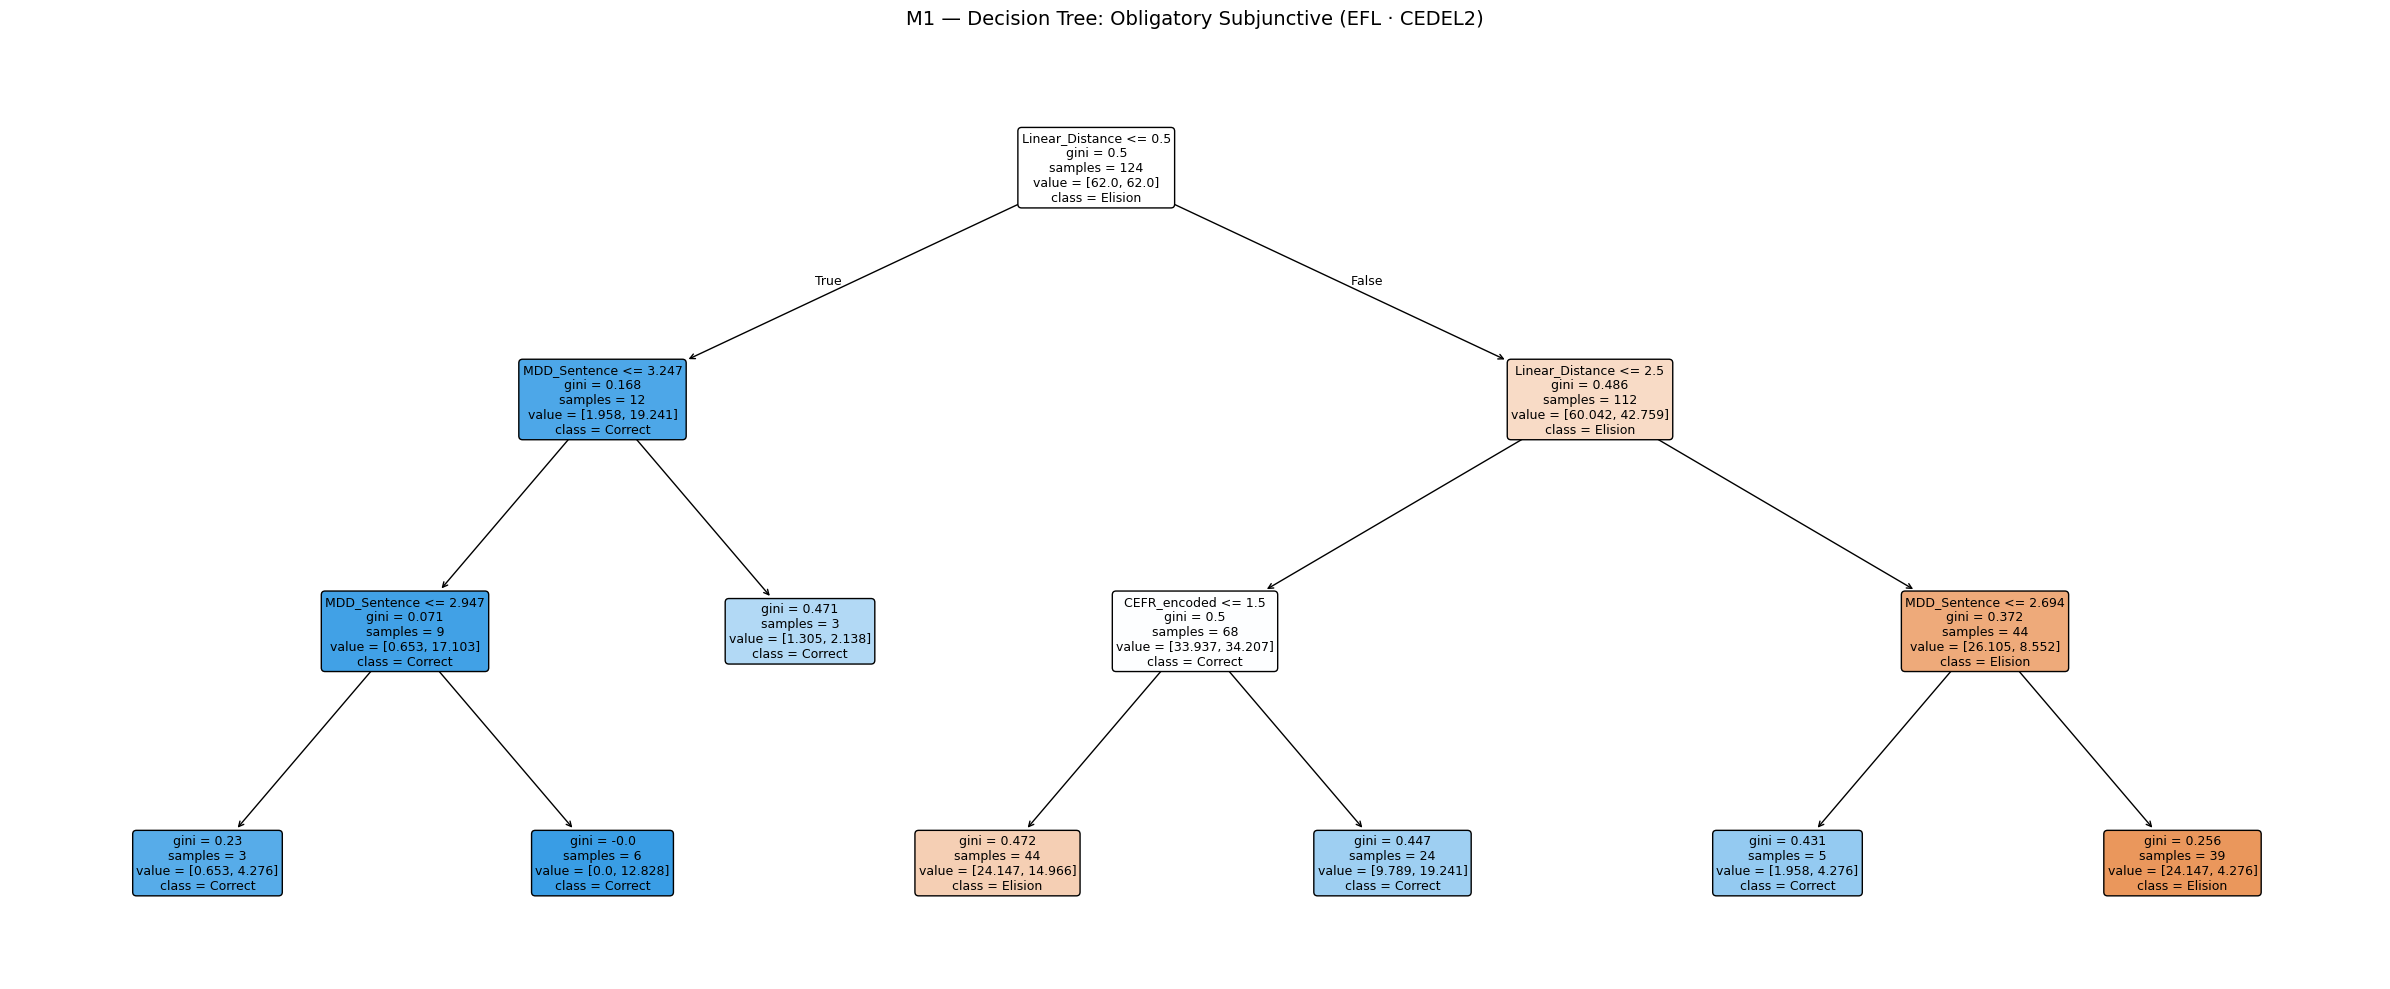

M1 tree saved → tree_M1_elision.png


In [19]:
# ════════════════════════════════════════════════════════════════
# STEP E — Export rules and visualise trees
# ════════════════════════════════════════════════════════════════

# Export decision rules as plain text
with open('tree_rules_M1.txt', 'w', encoding='utf-8') as f:
    if len(df_m1) >= 10:
        f.write(export_text(tree_m1, feature_names=FEATURES, max_depth=3))
    else:
        f.write("M1: insufficient cases to generate tree.\n")
print("M1 rules saved → tree_rules_M1.txt")

with open('tree_rules_M2.txt', 'w', encoding='utf-8') as f:
    if len(df_m2) >= 10 and n_classes_m2 >= 2:
        f.write(export_text(tree_m2, feature_names=FEATURES, max_depth=3))
    else:
        f.write("M2: insufficient cases or classes to generate tree.\n")
print("M2 rules saved → tree_rules_M2.txt")

# Visualise M1 tree
if len(df_m1) >= 10:
    fig, ax = plt.subplots(figsize=(24, 10))
    plot_tree(
        tree_m1,
        feature_names=FEATURES,
        class_names=['Elision', 'Correct'],
        filled=True, rounded=True, fontsize=9,
        ax=ax, impurity=True, proportion=False
    )
    plt.title('M1 — Decision Tree: Obligatory Subjunctive (EFL · CEDEL2)',
              fontsize=14, pad=20)
    plt.tight_layout()
    plt.savefig('tree_M1_elision.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("M1 tree saved → tree_M1_elision.png")

# Visualise M2 tree (only if trainable)
if len(df_m2) >= 10 and n_classes_m2 >= 2:
    fig, ax = plt.subplots(figsize=(24, 10))
    plot_tree(
        tree_m2,
        feature_names=FEATURES,
        class_names=['Correct', 'Hypercorrection'],
        filled=True, rounded=True, fontsize=9,
        ax=ax, impurity=True, proportion=False
    )
    plt.title('M2 — Decision Tree: Hypercorrection (EFL · CEDEL2)',
              fontsize=14, pad=20)
    plt.tight_layout()
    plt.savefig('tree_M2_hypercorrection.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("M2 tree saved → tree_M2_hypercorrection.png")